# Group Assigment II

Coca_cola_earning.csv dataset

## Plotting the data

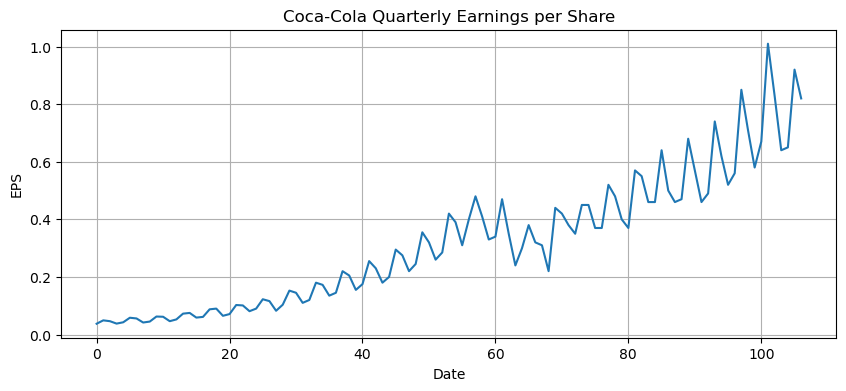

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.statespace.sarimax import SARIMAX
import warnings
warnings.filterwarnings("ignore")

# Load data
datos = pd.read_csv('coca_cola_earnings.csv', sep=";", decimal=",")
# datos['anntime'] = pd.to_datetime(datos['anntime'], format='%Y%m%d')
# datos.set_index('anntime', inplace=True)

# # Extract the time series
# y = datos['value']

y = datos.iloc[:, 1]  # or the column with your series
# Plot
plt.figure(figsize=(10, 4))
plt.plot(y)
plt.title("Coca-Cola Quarterly Earnings per Share")
plt.xlabel("Date")
plt.ylabel("EPS")
plt.grid(True)
plt.show()



In [2]:
# !pip install pmdarima

## PACF & ACF 

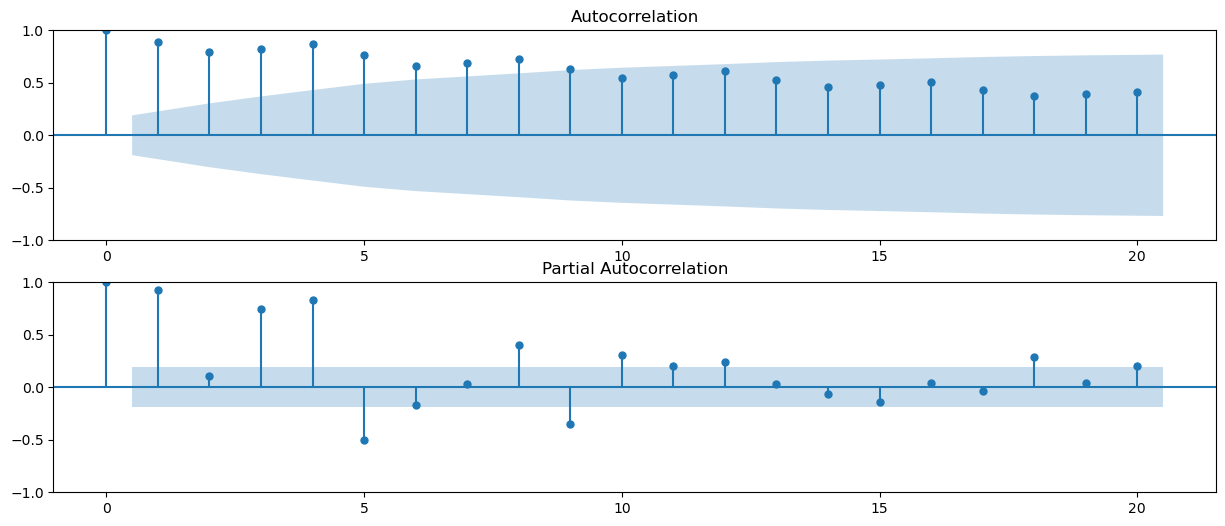

In [3]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

nlags = 20 # play with this parameter

# ValueError: Can only compute partial correlations for lags up to 50% of the sample size.

fig, ax = plt.subplots(2,1, figsize = (15,6))

plot_acf(y, lags = nlags, ax=ax[0])
plot_pacf(y, lags = nlags, method="ols", ax=ax[1])
plt.show()


## ADF TEST to test for Stationarity

In [4]:
import statsmodels as sm
import pmdarima
from pmdarima.arima import ndiffs, nsdiffs

# Ho: the process is not stationary. We need, at least, a unit root
# H1: the process is stationary. We have to check different models (lags)

adf_test = sm.tsa.stattools.adfuller(y, maxlag=10)
# Extract and round values
statistic = round(adf_test[0], 4)
p_value = round(adf_test[1], 4)
critical_values = adf_test[4]

# Print results
print("ADF Test for the Original Series")
print(f"Statistic Value: {statistic}")
print(f"P-Value: {p_value}")

# Conclusion
if p_value < 0.05:
    print("Conclusion: Reject the null hypothesis — the series is likely stationary.")
else:
    print("Conclusion: Fail to reject the null hypothesis — the series is likely non-stationary.")


ADF Test for the Original Series
Statistic Value: 1.0592
P-Value: 0.9949
Conclusion: Fail to reject the null hypothesis — the series is likely non-stationary.


## Regular & Seasonal Differences Recommendation

In [5]:
# Tests
s = 4
d = ndiffs(y, alpha = 0.05, test='adf')  # regular differences?
D = nsdiffs(y, m = s, test='ocsb') # # seasonal differences?

# Display results with explanation
print("Differencing Recommendations")
print(f"Suggested number of regular differences (d): {d}")
print(f"Suggested number of seasonal differences (D): {D}")


Differencing Recommendations
Suggested number of regular differences (d): 1
Suggested number of seasonal differences (D): 1


## SARIMAX 

                                      SARIMAX Results                                      
Dep. Variable:                               value   No. Observations:                  107
Model:             SARIMAX(0, 1, 2)x(0, 1, [1], 4)   Log Likelihood                 196.924
Date:                             Mon, 30 Jun 2025   AIC                           -385.849
Time:                                     22:25:40   BIC                           -375.349
Sample:                                          0   HQIC                          -381.597
                                             - 107                                         
Covariance Type:                               opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.2556      0.068     -3.766      0.000      -0.389      -0.123
ma.L2         -0.2781      

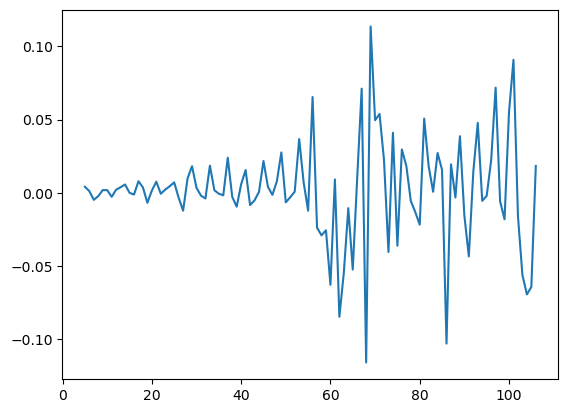

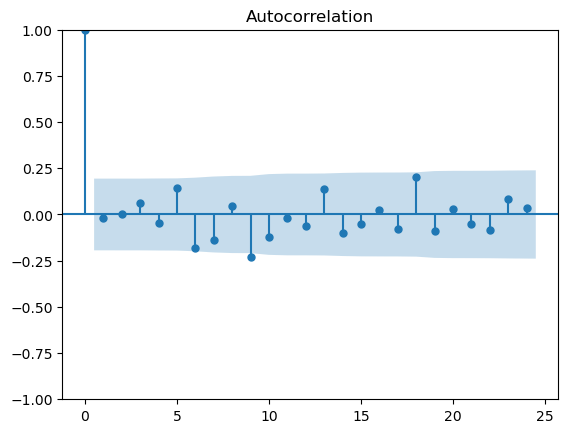

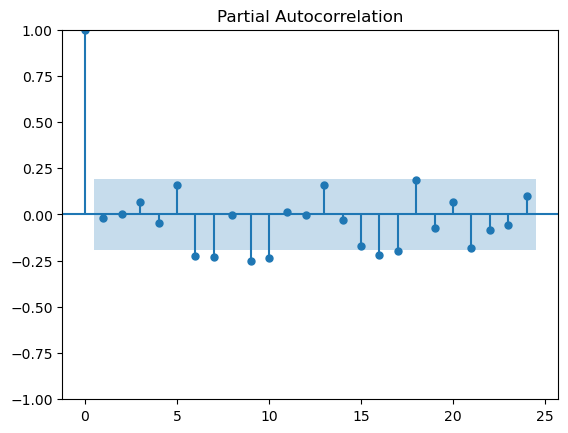

In [6]:
s = 4

fit = SARIMAX(endog = (y), order = (0,1,2), seasonal_order = (0,1,1,s)).fit()
print(fit.summary())
residuos = fit.resid[s+1:]

nlags=24 # i put 24 lags to see better the seasonality behaviour

plt.plot(residuos)
plt.show()
plot_acf(residuos, lags = nlags)
plt.show()
plot_pacf(residuos, method="ols",lags = nlags)
#plot_pacf(residuos,lags = nlags)
plt.show()

## ADF on residuals

In [7]:
#i added this code on my own after research, cannot verify 100%
from statsmodels.tsa.stattools import adfuller
# ADF test on residuals
adf_result = adfuller(fit.resid.dropna())
stat = round(adf_result[0], 4)
pvalue = round(adf_result[1], 6)
critical_values = adf_result[4]

# Output
print("\nADF Test on Model Residuals")
print(f"Test Statistic : {stat}")
print(f"P-Value        : {pvalue}")

# Interpretation
print("\nInterpretation:")
if pvalue < 0.05:
    print("The residuals are stationary (reject the null hypothesis).")
else:
    print("The residuals are not stationary (fail to reject the null hypothesis).")


ADF Test on Model Residuals
Test Statistic : -4.8555
P-Value        : 4.3e-05

Interpretation:
The residuals are stationary (reject the null hypothesis).


## LJUNG-BOX test for autocorrelation

In [8]:
import statsmodels.api as sm
from scipy.stats import shapiro
import seaborn as sns
import scipy.stats as st
import matplotlib.pyplot as plt
import numpy as np

# --- Ljung-Box test for autocorrelation ---
box_test = sm.stats.acorr_ljungbox(residuos, lags=[20], return_df=True)

stat_lb = round(box_test["lb_stat"].iloc[0], 4)
pval_lb = round(box_test["lb_pvalue"].iloc[0], 6)

print("\nLjung-Box Test (up to lag 20)")
print(f"Statistic Value : {stat_lb}")
print(f"P-Value         : {pval_lb}")

if pval_lb > 0.05:
    print("Residuals are likely uncorrelated (white noise).")
else:
    print("Residuals show autocorrelation — the model may not be fully capturing the data structure.")




Ljung-Box Test (up to lag 20)
Statistic Value : 28.1956
P-Value         : 0.10485
Residuals are likely uncorrelated (white noise).


## SHAPIRO for normality

In [9]:

# --- Shapiro-Wilk test for normality ---
shap_stat, shap_pval = shapiro(residuos)

print("\nShapiro-Wilk Test for Normality")
print(f"Statistic Value : {round(shap_stat, 4)}")
print(f"P-Value         : {round(shap_pval, 6)}")

if shap_pval > 0.05:
    print("Residuals appear normally distributed.")
else:
    print("Residuals deviate from normality - see plots")



Shapiro-Wilk Test for Normality
Statistic Value : 0.9236
P-Value         : 1.8e-05
Residuals deviate from normality - see plots


## Plot to see residuals histogram

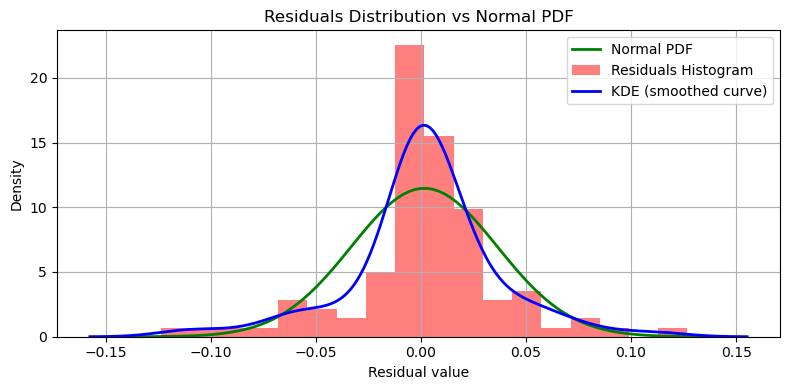

In [10]:
# --- Histogram + KDE + Normal PDF overlay ---
mean = np.mean(residuos)
std = np.std(residuos)
x = np.linspace(mean - 4*std, mean + 4*std, 100)
pdf = st.norm.pdf(x, mean, std)

plt.figure(figsize=(8, 4))
plt.plot(x, pdf, lw=2, color="green", label="Normal PDF")
plt.hist(residuos, density=True, bins=20, range=(mean - 4*std, mean + 4*std), color="red", alpha=0.5, label="Residuals Histogram")
sns.kdeplot(residuos, color="blue", lw=2, label="KDE (smoothed curve)")
plt.title("Residuals Distribution vs Normal PDF")
plt.xlabel("Residual value")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



## LJUNG-BOX for residuals (SWN)


📊 Ljung-Box Test on Squared Residuals (Lag 20)
-----------------------------------------------
Statistic Value : 49.8968
P-Value         : 0.000229
Evidence of autocorrelation in squared residuals


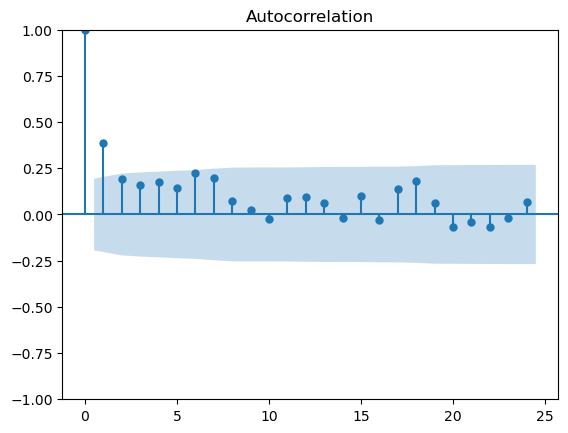

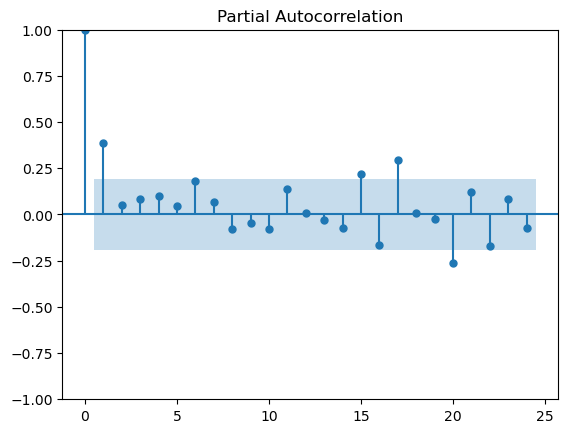

In [18]:
# Study the squared residuals for SWN

# --- Ljung-Box test on squared residuals (check for volatility clustering) ---
box_test2 = sm.stats.acorr_ljungbox(residuos**2, lags=[20], return_df=True)
stat_sq = round(box_test2["lb_stat"].iloc[0], 4)
pval_sq = round(box_test2["lb_pvalue"].iloc[0], 6)

print("\n📊 Ljung-Box Test on Squared Residuals (Lag 20)")
print("-----------------------------------------------")
print(f"Statistic Value : {stat_sq}")
print(f"P-Value         : {pval_sq}")


if pval_sq > 0.05:
    print("No significant autocorrelation in the squared residuals — variance looks stable.")
else:
    print("Evidence of autocorrelation in squared residuals")


plot_acf(residuos**2,lags=nlags)
plt.show()
plot_pacf(residuos**2,lags=nlags,method="ols")
plt.show()

## Plot of forecast with the whole data set

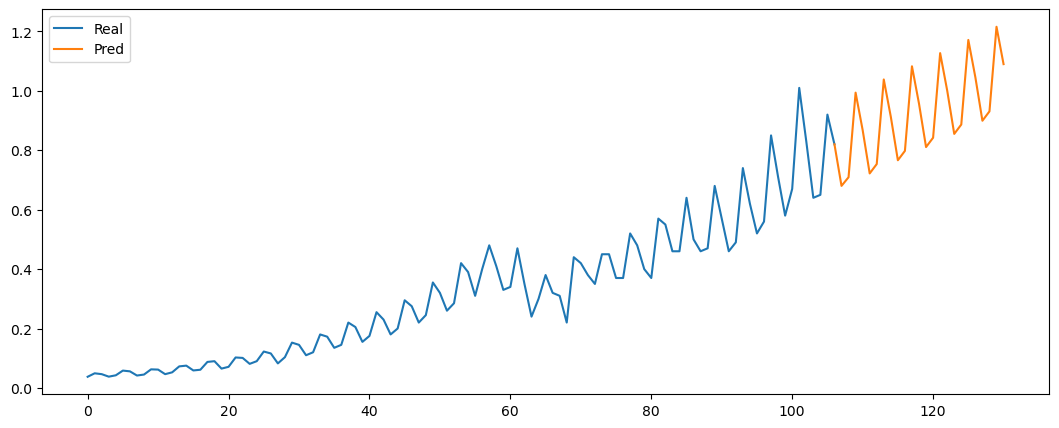

In [19]:
# Pintamos las siguientes 24 predicciones
y_pred = fit.forecast(steps = 24)

# Ponemos el último índice real
y_pred.loc[len(y)-1] = y[len(y)-1]
# Reseteamos los índices, ordenamos por índice y volvemos a poner el índice como índice de la Serie.
y_pred = y_pred.reset_index().sort_values(by = 'index').set_index('index')

# Las predicciones dan 0, el modelo arriba que está con todos los parámetros en 0 salvo
# el 's' no sé si dará algún problema en Python y no lo haga como en R o me he equivocado en otro sitio
# print(y_pred)
plt.figure(figsize = (13,5))
plt.plot(y, label = 'Real')
plt.plot(y_pred, label = 'Pred')
plt.legend()
plt.show()

## PLOT with the train data only

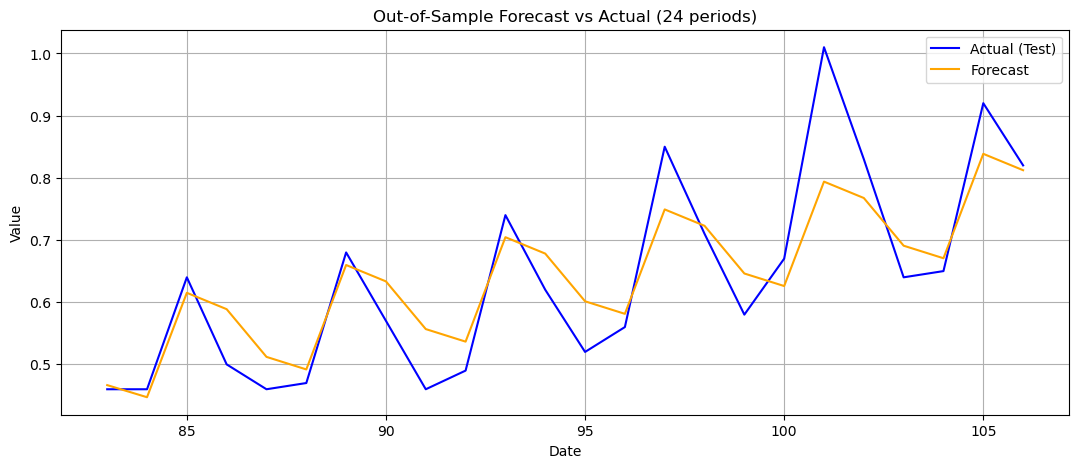

Forecast Evaluation Metrics
MSFE: 0.0049
MAPE (%): 8.4


In [25]:
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error

# 1. Split data into training and test (last 24 values for test)
n_test = 24
y_train = y[:-n_test]
y_test = y[-n_test:]

# 2. Fit the model on training data
fit = SARIMAX(y_train, order=(0, 1, 2), seasonal_order=(0, 1, 1, s)).fit()

# 3. Forecast the next 24 periods
forecast = fit.forecast(steps=n_test)

# 4. Assign proper index to forecast to match y_test
forecast.index = y_test.index  # ensures aligned plotting and metric comparison

# 5. Plot the real vs forecasted values (only on test set)
plt.figure(figsize=(13, 5))
plt.plot(y_test, label='Actual (Test)', color='blue')
plt.plot(forecast, label='Forecast', color='orange')
plt.title("Out-of-Sample Forecast vs Actual (24 periods)")
plt.xlabel("Date")
plt.ylabel("Value")
plt.grid(True)
plt.legend()
plt.show()

# 6. Forecast accuracy metrics
msfe = mean_squared_error(y_test, forecast)
mape = mean_absolute_percentage_error(y_test, forecast) * 100

print("Forecast Evaluation Metrics")
print("MSFE:", round(msfe, 4))
print("MAPE (%):", round(mape, 2))


## Additional diagnostics


In [21]:
# MORE FORECAST INFORMATION

forecast_result = fit.get_forecast(steps=4)
y_pred = forecast_result.predicted_mean
conf_int = forecast_result.conf_int(alpha=0.05)  
stderr = forecast_result.se_mean 

print("point predictions")
print(y_pred)
print("standard error of point predictions")
print(stderr)
print("confidence intervals around point predictions")
print(conf_int)


point predictions
107    0.680136
108    0.709204
109    0.993987
110    0.868237
Name: predicted_mean, dtype: float64
standard error of point predictions
107    0.034828
108    0.043418
109    0.046356
110    0.049119
Name: var_pred_mean, dtype: float64
confidence intervals around point predictions
     lower value  upper value
107     0.611875     0.748397
108     0.624107     0.794302
109     0.903131     1.084843
110     0.771966     0.964508


In [22]:
# MORE FORECAST INFORMATION

media = np.mean(residuos)
desviacion_std = np.std(residuos)

# Standardized residuals
residuos_estand = (residuos - media) / desviacion_std

# Verification
#print("Standardized residuals:", residuos_estand)
print("Mean:", np.mean(residuos_estand))
print("Standard deviation:", np.std(residuos_estand))


quantile_2_5=np.quantile(residuos_estand, 0.025)
quantile_97_5=np.quantile(residuos_estand, 0.975)

print("We must compare the following numbers with +/- 1.96 from the standard normal")
print(quantile_2_5,quantile_97_5)

Mean: 2.1769078914218755e-18
Standard deviation: 1.0
We must compare the following numbers with +/- 1.96 from the standard normal
-2.2506619886307138 2.0094319088883403
